In [32]:
from transformers import BertForQuestionAnswering
from transformers import BertTokenizer
import numpy as np
import torch
import json

## Load model and tokenizer

In [2]:
model_name = "bert-large-uncased-whole-word-masking-finetuned-squad"

In [3]:
model = BertForQuestionAnswering.from_pretrained(model_name)

config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForQuestionAnswering LOAD REPORT from: bert-large-uncased-whole-word-masking-finetuned-squad
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [4]:
tokenizer = BertTokenizer.from_pretrained(model_name)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

## Embeddings

In [7]:
# example question and text containing the answer
question = "When was the first dvd released?"
with open('bert_lesson_text.txt', 'r') as file:
    answer_document = file.readline()
    print(answer_document)

The first DVD (Digital Versatile Disc) was released on March 24, 1997. It was a movie titled 'Twister' and was released in Japan. DVDs quickly gained popularity as a replacement for VHS tapes and became a common format for storing and distributing digital video and data.



In [8]:
encoding = tokenizer(
    text=question,
    text_pair=answer_document,
    add_special_tokens=True,      # Automatically adds [CLS] and [SEP] tokens
    padding="max_length",         # Pads short inputs up to the max_length
    truncation=True,              # Truncates inputs longer than the max_length
    return_attention_mask=True,   # Generates attention mask for the model
    return_tensors="pt"           # Generates native PyTorch ('pt') tensors
)

In [16]:
print(encoding)

{'input_ids': tensor([[  101,  2043,  2001,  1996,  2034,  4966,  2207,  1029,   102,  1996,
          2034,  4966,  1006,  3617, 22979,  5860,  1007,  2001,  2207,  2006,
          2233,  2484,  1010,  2722,  1012,  2009,  2001,  1037,  3185,  4159,
          1005,  9792,  2121,  1005,  1998,  2001,  2207,  1999,  2900,  1012,
         22477,  2855,  4227,  6217,  2004,  1037,  6110,  2005, 17550, 13324,
          1998,  2150,  1037,  2691,  4289,  2005, 23977,  1998, 20083,  3617,
          2678,  1998,  2951,  1012,   102,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,  

In [17]:
inputs = encoding['input_ids']
sentence_embedding = encoding['token_type_ids']

# inputs is already a 2D tensor. We extract the first sequence (1D) using inputs[0] to convert back to tokens.
tokens = tokenizer.convert_ids_to_tokens(inputs[0])

In [18]:
tokenizer.decode(101)

'[CLS]'

In [19]:
tokenizer.decode(102)

'[SEP]'

In [21]:
# Pass the already-formed PyTorch tensors directly to the model
output = model(input_ids = inputs, token_type_ids = sentence_embedding)

## Model output

In [22]:
start_index = torch.argmax(output.start_logits)
end_index = torch.argmax(output.end_logits)

print(start_index)
print(end_index)

tensor(20)
tensor(23)


In [23]:
answer = ' '.join(tokens[start_index:end_index+1])
print(answer)

march 24 , 1997


In [24]:
import matplotlib as plt
import seaborn as sns

In [25]:
s_scores = output.start_logits.detach().numpy().flatten()
e_scores = output.end_logits.detach().numpy().flatten()

In [26]:
token_labels = []
for (i, token) in enumerate(tokens):
    token_labels.append('{:} - {:>2}'.format(token, i))

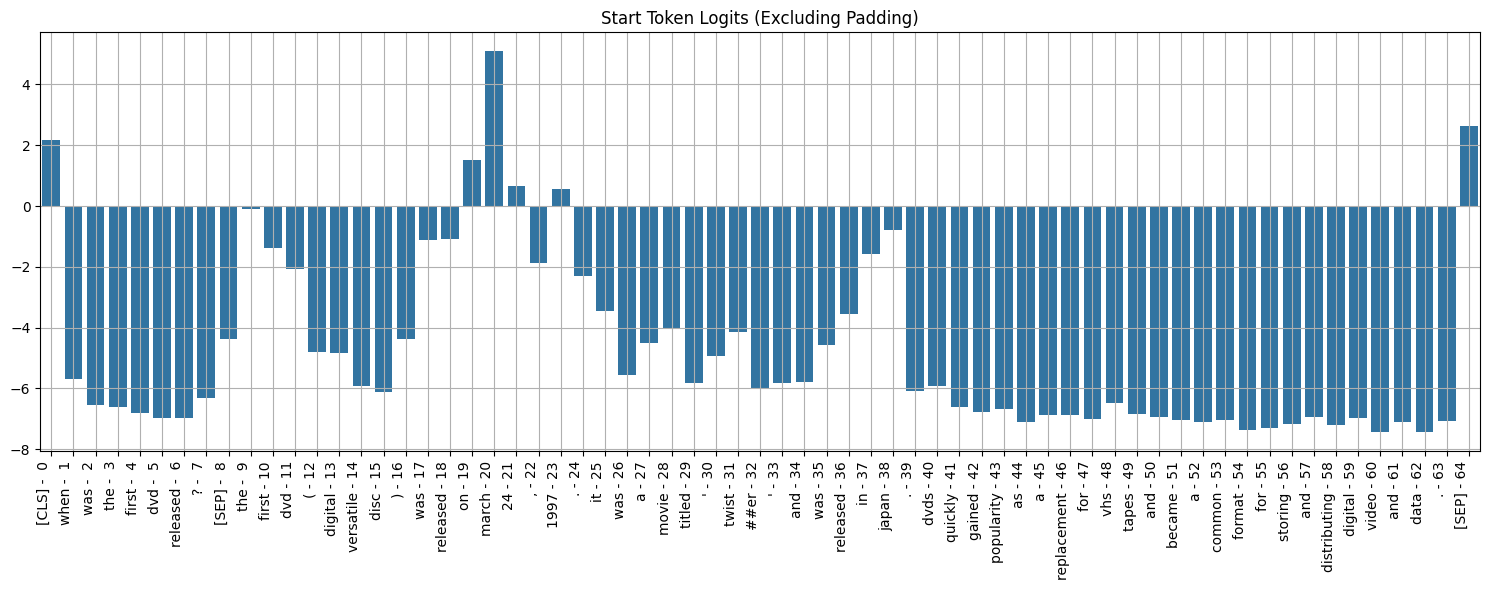

In [30]:
# Find the index of the first [PAD] token to exclude padding from the visualization
non_pad_length = tokens.index('[PAD]') if '[PAD]' in tokens else len(tokens)

filtered_labels = token_labels[:non_pad_length]
filtered_s_scores = s_scores[:non_pad_length]

# Plot the start scores for non-padding tokens
plt.figure(figsize=(15, 6))
ax = sns.barplot(x=filtered_labels, y=filtered_s_scores)
ax.set_xticks(np.arange(len(filtered_labels)))
ax.set_xticklabels(filtered_labels, rotation=90, ha="right")
ax.set_title("Start Token Logits (Excluding Padding)")
ax.grid(True)
plt.tight_layout()
plt.show()

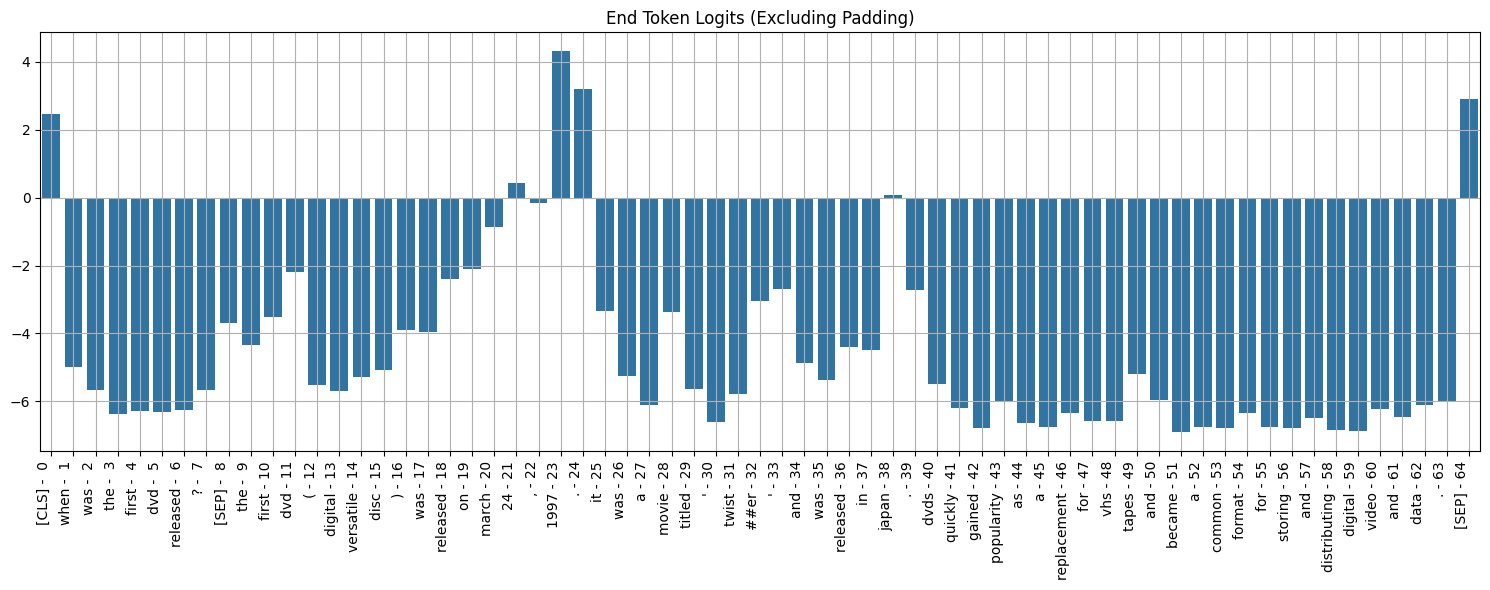

In [31]:
# Find the index of the first [PAD] token to exclude padding from the visualization
non_pad_length = tokens.index('[PAD]') if '[PAD]' in tokens else len(tokens)

filtered_labels = token_labels[:non_pad_length]
filtered_e_scores = e_scores[:non_pad_length]

# Plot the end scores for non-padding tokens
plt.figure(figsize=(15, 6))
ax = sns.barplot(x=filtered_labels, y=filtered_e_scores)
ax.set_xticks(np.arange(len(filtered_labels)))
ax.set_xticklabels(filtered_labels, rotation=90, ha="right")
ax.set_title("End Token Logits (Excluding Padding)")
ax.grid(True)
plt.tight_layout()
plt.show()

## Question Answering

In [34]:
with open('bert_lesson_text.txt', 'r') as file:
    ignore_1 = file.readline()
    ignore_2 = file.readline()
    sunset_motors_context = file.readline()
    print(sunset_motors_context)

Sunset Motors is a renowned automobile dealership that has been a cornerstone of the automotive industry since its establishment in 1978. Located in the picturesque town of Crestwood, nestled in the heart of California's scenic Central Valley, Sunset Motors has built a reputation for excellence, reliability, and customer satisfaction over the past four decades. Founded by visionary entrepreneur Robert Anderson, Sunset Motors began as a humble, family-owned business with a small lot of used cars. However, under Anderson's leadership and commitment to quality, it quickly evolved into a thriving dealership offering a wide range of vehicles from various manufacturers. Today, the dealership spans over 10 acres, showcasing a vast inventory of new and pre-owned cars, trucks, SUVs, and luxury vehicles. One of Sunset Motors' standout features is its dedication to sustainability. In 2010, the dealership made a landmark decision to incorporate environmentally friendly practices, including solar p

In [35]:
def faq_bot(question):

    context = sunset_motors_context
    input_ids = tokenizer.encode(question, context)
    tokens = tokenizer.convert_ids_to_tokens(input_ids)
    sep_idx = input_ids.index(tokenizer.sep_token_id)
    num_seg_a = sep_idx+1
    num_seg_b = len(input_ids) - num_seg_a
    segment_ids = [0]*num_seg_a + [1]*num_seg_b
    output = model(torch.tensor([input_ids]), token_type_ids = torch.tensor([segment_ids]))
    answer_start = torch.argmax(output.start_logits)
    answer_end = torch.argmax(output.end_logits)
    if answer_end >= answer_start:
        answer = ' '.join(tokens[answer_start:answer_end+1])
    else:
        print("I don't know how to answer this question, can you ask another one?")
    corrected_answer = ''
    for word in answer.split():
        if word[0:2] == '##':
            corrected_answer += word[2:]
        else:
            corrected_answer += ' ' + word
    return corrected_answer

In [36]:
faq_bot("Where is the dealership located?")

' crestwood'

In [37]:
faq_bot("what make of cars are available?")

' ford , toyota , honda , chevrolet , and bmw'

In [38]:
faq_bot("how large is the dealership?")

' 10 acres'

## RoBERTa and DistilBERT

In [40]:
from transformers import RobertaTokenizer, RobertaModel
model_name = "roberta-base"
tokenizer = RobertaTokenizer.from_pretrained(model_name)
model = RobertaModel.from_pretrained(model_name)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [41]:
from transformers import DistilBertTokenizer, DistilBertModel
model_name = "distilbert-base-uncased"
tokenizer =  DistilBertTokenizer.from_pretrained(model_name)
model = DistilBertModel.from_pretrained(model_name)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
